(p5-lab-unsupervised-learning)=
# P5 실습: 비지도 학습과 K-평균 군집화

**실습 목표**

정답 레이블 없이 데이터를 탐색하고, K-평균의 **할당·중심 갱신**을 직접 계산한 뒤, 사이킷런으로 군집을 학습한다. 마지막에는 **특성 스케일·군집 수·군집 모양**이 결과에 어떤 영향을 주는지 확인한다.

코드 셀을 위에서부터 실행하고 각 단계의 **확인 질문**에 답하라. 예제 데이터는 모두 노트북에서 불러오거나 생성한다.

**환경설정**

필요한 라이브러리를 불러온다.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_blobs, make_moons
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

## 1단계: 정답 없는 데이터에서 군집을 찾아본다

붓꽃 자료에서 **꽃잎 길이와 너비**만 먼저 그려 보자. 이때 품종 레이블은 사용하지 않는다.

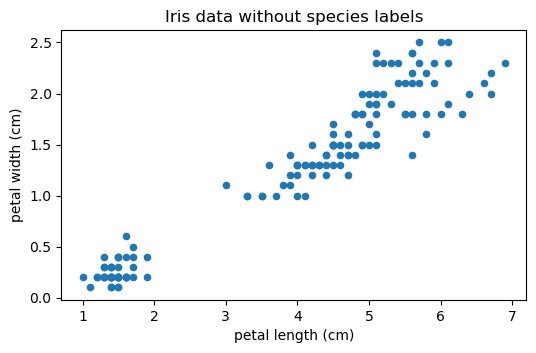

In [2]:
iris = load_iris(as_frame=True)
X_iris = iris.data[["petal length (cm)", "petal width (cm)"]]

X_iris.plot.scatter(x="petal length (cm)", y="petal width (cm)", figsize=(6, 3.5))
plt.title("Iris data without species labels")
plt.show()

### K-평균으로 묶어 본다

다음 코드의 `n_clusters=3`은 **예시를 위한 설정**이다. 실제 군집 수의 정답을 알고 지정한 것은 아니다.

c:\Users\gslee\miniforge3\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


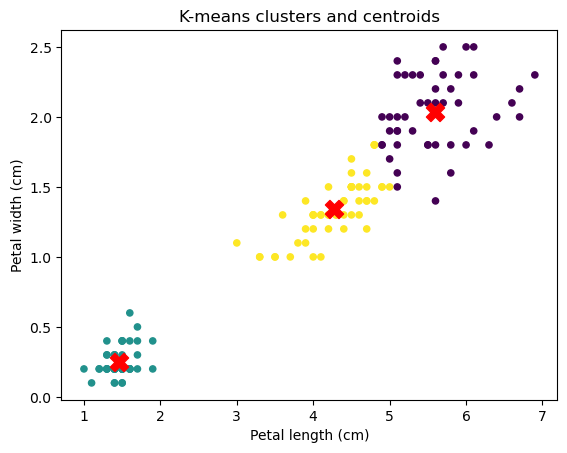

In [3]:
iris_model = KMeans(n_clusters=3, n_init=10, random_state=42)
iris_group = iris_model.fit_predict(X_iris)

plt.scatter(X_iris.iloc[:, 0], X_iris.iloc[:, 1], c=iris_group, s=20)
plt.scatter(iris_model.cluster_centers_[:, 0], iris_model.cluster_centers_[:, 1],
            marker="X", s=170, c="red")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("K-means clusters and centroids")
plt.show()

### 실제 품종과 군집 번호는 같은가?

이제 **학습에 사용하지 않은** 실제 품종 레이블을 색으로 표시해 보자. K-평균의 군집 번호와 품종 번호가 다르더라도 모델의 실행 오류는 아니다.

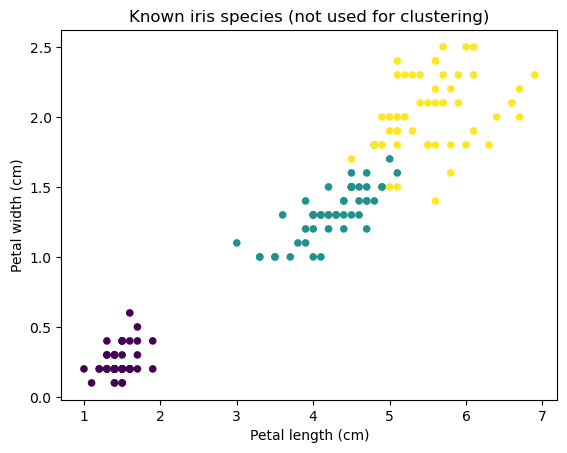

In [4]:
plt.scatter(X_iris.iloc[:, 0], X_iris.iloc[:, 1], c=iris.target, s=20)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Known iris species (not used for clustering)")
plt.show()

**확인 질문**

- K-평균은 품종 레이블 없이 무엇을 비교했는가?
- 군집 `0`이 실제 품종 `0`을 뜻하지 않는 이유는 무엇인가?

## 2단계: K-평균의 할당과 중심 갱신을 계산한다

이번에는 **10개 점**을 사용한다. 각 점 옆의 숫자는 표에서 해당 점의 **행 번호**다.

K-평균은 시작할 때 **초기 센트로이드의 위치를 정해야 한다.** 여기서는 계산 과정을 쉽게 살펴보기 위해 **두 중심을 `(0, 0)`과 `(6, 5)`로 임의로 지정한다.** 아직 군집을 분석해서 얻은 중심은 아니다. 처음 정한 위치에서 출발해 **가까운 중심에 할당 → 배정된 점들의 평균으로 중심 갱신 → 다시 할당**하는 과정을 살펴보자.

센트로이드는 군집에 속한 점들의 **좌표 평균**이므로, 이동한 위치에 실제 샘플이 없을 수도 있다.

산점도의 **파란 점(군집 0)**과 **주황 점(군집 1)**은 각 샘플을 **가장 가까운 초기 센트로이드에 처음 할당한 결과**다. 주황 점은 `3`, `4`, `5`, `8`, `9`번이고, 나머지는 파란 점이다. **센트로이드는 빨간 X**로 표시한다. 다음 거리 표에서 이 할당이 맞는지 확인하라.

**참고:** 0번과 4번 샘플은 초기 센트로이드와 좌표가 같아서 빨간 X와 겹쳐 보인다. X를 빈 모양으로 표시하여 두 샘플의 군집 색상도 볼 수 있도록 했다.


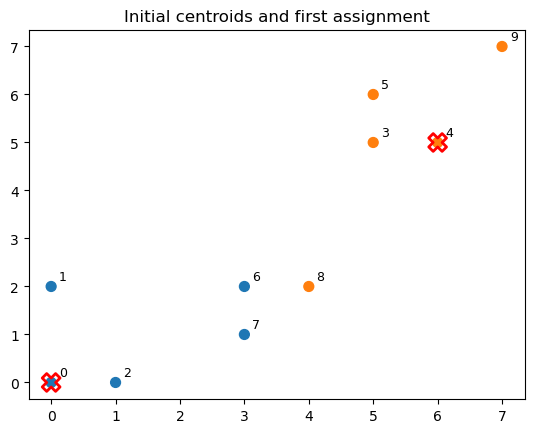

In [5]:
small = pd.DataFrame({
    "x": [0, 0, 1, 5, 6, 5, 3, 3, 4, 7],
    "y": [0, 2, 0, 5, 5, 6, 2, 1, 2, 7]
})
initial = pd.DataFrame({"x": [0, 6], "y": [0, 5]})

distances = pd.DataFrame({
    "center_0": np.sqrt(((small - initial.iloc[0]) ** 2).sum(axis=1)),
    "center_1": np.sqrt(((small - initial.iloc[1]) ** 2).sum(axis=1))
})
group = distances.idxmin(axis=1)

plt.scatter(small["x"], small["y"],
            c=group.map({"center_0": "tab:blue", "center_1": "tab:orange"}), s=50)
for i, point in small.iterrows():
    plt.text(point["x"] + 0.12, point["y"] + 0.12, str(i), fontsize=9)
plt.scatter(initial["x"], initial["y"], marker="X", s=165,
            facecolors="none", edgecolors="red", linewidths=2)
plt.title("Initial centroids and first assignment")
plt.show()

### 가장 가까운 센트로이드에 할당한다

각 점에서 중심 0과 중심 1까지의 유클리드 거리를 확인하라. 아래 표는 앞 그림에서 사용한 **첫 번째 군집 할당 결과**다. `idxmin(axis=1)`은 **각 행에서 값이 가장 작은 열 이름**을 반환한다.


In [6]:
pd.concat([small, distances.round(2), group.rename("assigned")], axis=1)

,x,y,center_0,center_1,assigned
0,0,0,0.00,7.81,center_0
1,0,2,2.00,6.71,center_0
2,1,0,1.00,7.07,center_0
3,5,5,7.07,1.00,center_1
4,6,5,7.81,0.00,center_1
5,5,6,7.81,1.41,center_1
6,3,2,3.61,4.24,center_0
7,3,1,3.16,5.00,center_0
8,4,2,4.47,3.61,center_1
9,7,7,9.90,2.24,center_1


### 배정된 점들의 평균으로 중심을 옮긴다

같은 그룹에 배정된 점들의 좌표를 평균 내면 **새 센트로이드**를 얻는다.

In [7]:
new_centers = small.groupby(group).mean()
print("처음 중심")
print(initial)
print("갱신한 중심")
print(new_centers.round(2))

처음 중심
   x  y
0  0  0
1  6  5
갱신한 중심
            x    y
center_0  1.4  1.0
center_1  5.4  5.0


### 센트로이드는 실제로 어디로 이동했을까?

처음 정한 중심과 **배정된 점들의 평균으로 갱신한 중심**을 같은 산점도에 표시하자.

- **검은색 빈 X:** 처음 임의로 정한 센트로이드
- **빨간색 X:** 처음 할당된 점들의 평균으로 이동한 센트로이드
- **화살표:** 센트로이드가 이동한 방향

색이 같은 작은 점들은 **첫 번째 할당에서 같은 군집으로 묶인 샘플**이다. 갱신된 센트로이드의 위치에 실제 샘플이 있는지도 확인하라.

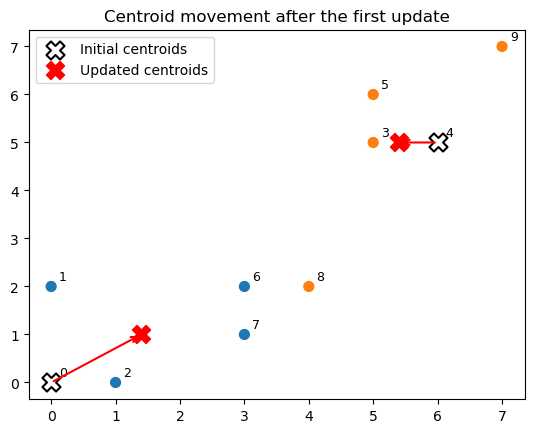

In [8]:
plt.scatter(small["x"], small["y"],
            c=group.map({"center_0": "tab:blue", "center_1": "tab:orange"}), s=50)
for i, point in small.iterrows():
    plt.text(point["x"] + 0.12, point["y"] + 0.12, str(i), fontsize=9)

plt.scatter(initial["x"], initial["y"], marker="X", s=170,
            facecolors="white", edgecolors="black", linewidths=1.5,
            label="Initial centroids")
plt.scatter(new_centers["x"], new_centers["y"], marker="X", s=170,
            c="red", label="Updated centroids")

for i, name in enumerate(new_centers.index):
    plt.annotate("",
                 xy=(new_centers.loc[name, "x"], new_centers.loc[name, "y"]),
                 xytext=(initial.loc[i, "x"], initial.loc[i, "y"]),
                 arrowprops={"arrowstyle": "->", "color": "red", "lw": 1.5})

plt.title("Centroid movement after the first update")
plt.legend()
plt.show()

### 갱신한 중심을 기준으로 다시 할당한다

한 번 중심을 갱신했다고 끝나는 것은 아니다. **새 중심까지의 거리를 다시 계산**하여 군집을 정하고, 필요하면 중심도 다시 갱신한다. 이번 예시에서는 **배정이 바뀐 점이 있는지** 확인하고, 그 점을 위 그래프에서 찾아보자.

In [9]:
second_distances = pd.DataFrame({
    "center_0": np.sqrt(((small - new_centers.loc["center_0"]) ** 2).sum(axis=1)),
    "center_1": np.sqrt(((small - new_centers.loc["center_1"]) ** 2).sum(axis=1))
})
second_group = second_distances.idxmin(axis=1)

print("할당이 바뀐 점의 수:", (group != second_group).sum())
pd.DataFrame({"첫 번째 할당": group, "두 번째 할당": second_group})

할당이 바뀐 점의 수: 1


,첫 번째 할당,두 번째 할당
0,center_0,center_0
1,center_0,center_0
2,center_0,center_0
3,center_1,center_1
4,center_1,center_1
5,center_1,center_1
6,center_0,center_0
7,center_0,center_0
8,center_1,center_0
9,center_1,center_1


### `KMeans`는 이 반복을 자동으로 수행한다

지금은 중심을 한 번 옮긴 뒤 다시 할당했다. 만약 할당이 달라졌다면 다시 평균을 내어 중심을 갱신할 수 있다. **할당과 중심이 더 이상 바뀌지 않거나 종료 조건에 도달하면** 반복을 멈춘다. 사이킷런의 `KMeans`가 이 과정을 수행한다.

초기값과 군집 번호는 달라질 수 있으므로 아래에서는 **학습된 중심 좌표와 관성**을 확인하자.

In [10]:
small_model = KMeans(n_clusters=2, n_init=10, random_state=42)
small_model.fit(small)
print("학습된 중심:")
print(pd.DataFrame(small_model.cluster_centers_, columns=["x", "y"]).round(2))
print("관성:", round(small_model.inertia_, 2))
print("군집 번호:", small_model.labels_)

학습된 중심:
      x     y
0  5.75  5.75
1  1.83  1.17
관성: 25.17
군집 번호: [1 1 1 0 0 0 1 1 1 0]


### 모든 중심과의 거리, 새 점의 군집

`transform()`은 **각 센트로이드까지의 거리**, `predict()`는 가장 가까운 **센트로이드의 번호**를 알려준다. `predict()`는 중심을 다시 학습하지 않는다.

In [11]:
new_point = pd.DataFrame({"x": [0.5], "y": [1.0]})
print("각 중심까지의 거리:", small_model.transform(new_point).round(2))
print("배정 군집:", small_model.predict(new_point))

각 중심까지의 거리: [[7.08 1.34]]
배정 군집: [1]


**확인 질문**

- 새로운 중심의 좌표는 어떻게 계산했는가?
- 새 중심으로 다시 할당했을 때 바뀐 점은 몇 개인가? 어떤 점이 왜 다른 군집으로 이동했는가?
- 센트로이드는 실제 관측된 점 중 하나여야 하는가?
- `transform()`과 `predict()`는 무엇이 다른가?

## 3단계: 특성의 표현이 거리를 어떻게 바꾸는가?

K-평균은 점 사이의 **유클리드 거리**를 사용한다. 같은 데이터라도 어떤 특성을 사용하고 어떻게 변환하느냐에 따라 가까운 대상이 달라진다. 먼저 숫자가 작은 예시로 직접 확인하자.

### 방문객 수와 만족도: 표준화 전후의 거리

네 가게의 **하루 방문객 수**와 **만족도(5점 만점)**를 비교한다. A와 B는 방문객 수가 다르고, A와 C는 만족도가 다르다. 숫자 크기가 크게 다른 두 특성을 그대로 사용하면 어떤 차이가 나타날까?

In [12]:
stores = pd.DataFrame({
    "방문객": [100, 200, 100, 200],
    "만족도": [4, 4, 3, 3]
}, index=["A", "B", "C", "D"])

stores

,방문객,만족도
A,100,4
B,200,4
C,100,3
D,200,3


먼저 A–B와 A–C의 원래 거리를 계산하자. `np.linalg.norm()`은 두 좌표를 뺀 결과의 **유클리드 거리**를 계산한다.

In [13]:
raw_AB = np.linalg.norm(stores.loc["A"] - stores.loc["B"])
raw_AC = np.linalg.norm(stores.loc["A"] - stores.loc["C"])

print("원래 거리 A–B:", raw_AB)
print("원래 거리 A–C:", raw_AC)

원래 거리 A–B: 100.0
원래 거리 A–C: 1.0


이제 `StandardScaler`로 **특성(열)별 평균을 빼고 표준편차로 나누어** 보자. 변환된 좌표를 사용해 같은 두 거리를 다시 계산한다.

In [14]:
scaled = pd.DataFrame(
    StandardScaler().fit_transform(stores),
    index=stores.index, columns=stores.columns
)

scaled_AB = np.linalg.norm(scaled.loc["A"] - scaled.loc["B"])
scaled_AC = np.linalg.norm(scaled.loc["A"] - scaled.loc["C"])

print("표준화한 좌표")
print(scaled)
pd.DataFrame({
    "원래 거리": [raw_AB, raw_AC],
    "표준화 후 거리": [scaled_AB, scaled_AC]
}, index=["A–B", "A–C"]).round(2)

표준화한 좌표
   방문객  만족도
A -1.0  1.0
B  1.0  1.0
C -1.0 -1.0
D  1.0 -1.0


,원래 거리,표준화 후 거리
A–B,100.0,2.0
A–C,1.0,2.0


**관찰할 것:** 원래 거리는 A–B가 100, A–C가 1이지만, 표준화 후에는 두 거리 모두 2다. **표준화는 각 열의 수치 범위에 따른 영향력을 조정**한다. 다만 표준화가 언제나 최선이거나 두 특성의 중요성을 정확히 같게 만든다는 뜻은 아니다.

### 거리의 차이가 군집화 결과에도 영향을 줄까?

이번에는 점이 많은 인공 데이터에서 한 특성의 값만 100배 키운 다음, 표준화 전후의 K-평균 결과를 비교하자.

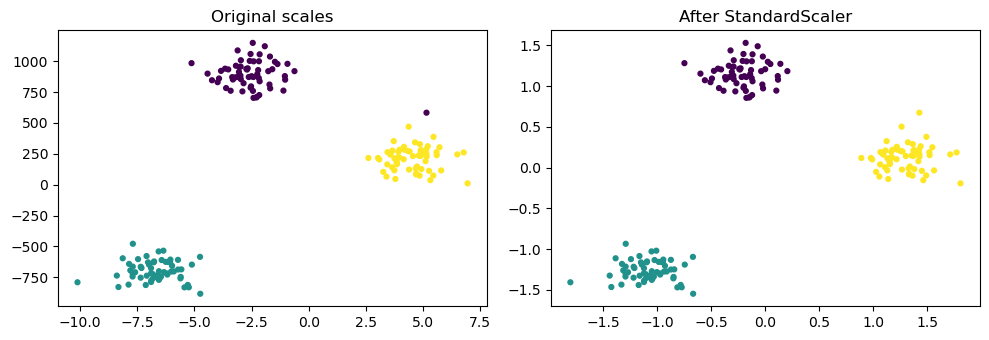

In [15]:
points, _ = make_blobs(n_samples=180, centers=3, cluster_std=1.0, random_state=42)
X_scale = pd.DataFrame(points, columns=["x", "y"])
X_scale["y"] *= 100

raw_group = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_scale)
X_std = pd.DataFrame(StandardScaler().fit_transform(X_scale), columns=X_scale.columns)
std_group = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_std)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(X_scale["x"], X_scale["y"], c=raw_group, s=12)
axes[0].set_title("Original scales")
axes[1].scatter(X_std["x"], X_std["y"], c=std_group, s=12)
axes[1].set_title("After StandardScaler")
plt.tight_layout()
plt.show()

### 상품 판매건수: 전체 규모와 구성 비율

판매점 P와 Q는 **상품 구성 비율은 같지만** 판매량이 10배 다르다. 반면 Q와 R은 **총판매량은 같지만** 상품 구성이 다르다.

| 판매점 | 상품 1 | 상품 2 |
|---|---:|---:|
| P | 800 | 200 |
| Q | 80 | 20 |
| R | 20 | 80 |

원래 건수의 거리와 각 행을 합계로 나눈 비중의 거리를 모두 계산해 보자.

In [16]:
counts = pd.DataFrame({
    "상품 1": [800, 80, 20],
    "상품 2": [200, 20, 80]
}, index=["P", "Q", "R"])

shares = counts.div(counts.sum(axis=1), axis=0)
print("원래 건수")
print(counts)
print("행별 비중")
print(shares)

원래 건수
   상품 1  상품 2
P   800   200
Q    80    20
R    20    80
행별 비중
   상품 1  상품 2
P   0.8   0.2
Q   0.8   0.2
R   0.2   0.8


In [17]:
pd.DataFrame({
    "원래 거리": [
        np.linalg.norm(counts.loc["P"] - counts.loc["Q"]),
        np.linalg.norm(counts.loc["Q"] - counts.loc["R"])
    ],
    "비중 변환 후 거리": [
        np.linalg.norm(shares.loc["P"] - shares.loc["Q"]),
        np.linalg.norm(shares.loc["Q"] - shares.loc["R"])
    ]
}, index=["P–Q", "Q–R"]).round(2)

,원래 거리,비중 변환 후 거리
P–Q,742.16,0.00
Q–R,84.85,0.85


**관찰할 것:** 원래 건수에서는 Q–R이 더 가깝지만, 비중으로 바꾸면 **P–Q의 거리가 0**이 된다. 비중 변환은 행마다 전체량을 1로 만들어 **구성 비율**을 비교한다. 대신 판매 규모가 10배 차이 난다는 정보는 사라진다.

**확인 질문**

- 표준화에서는 각 **열**을 기준으로 무엇을 계산했는가?
- 비중 변환에서는 각 **행**을 무엇으로 나누었는가?
- 판매량이 큰 판매점끼리 묶으려면 건수와 비중 중 어떤 표현이 더 적절한가?
- 두 변환 중 하나가 언제나 정답이라고 할 수 없는 이유는 무엇인가?

## 4단계: 관성과 실루엣 점수로 군집 수를 비교한다

군집 수는 `k=2`부터 `6`까지 비교한다. **관성**은 중심까지의 제곱 거리 합계이고, **실루엣 점수**는 군집 내부의 가까움과 군집 간의 분리 정도를 반영한다.

실루엣 점수는 널리 사용하는 **보조 지표**이지만, 점수만으로 실제 군집 수가 확정되는 것은 아니다.

### 실루엣 계수를 직접 계산해 본다

한 점에서 **같은 군집의 다른 점들까지의 평균 거리**를 `a`, **가장 가까운 다른 군집까지의 평균 거리**를 `b`라고 하자. 이 점의 실루엣 계수는 다음과 같다.

$$
s=\frac{b-a}{\max(a,b)}
$$

`a=2`, `b=5`인 점의 실루엣 계수를 직접 계산해 보자. 이는 **한 점의 계수**이며, 전체 실루엣 점수는 모든 점의 계수를 평균한 값이다.

In [18]:
a = 2
b = 5
s = (b - a) / max(a, b)
print("한 점의 실루엣 계수:", s)

한 점의 실루엣 계수: 0.6


In [19]:
X_blob, _ = make_blobs(
    n_samples=240, centers=[[-4, -1], [0, 3], [4, -1]],
    cluster_std=0.8, random_state=42
)
X_blob = pd.DataFrame(X_blob, columns=["x", "y"])

rows = []
for k in range(2, 7):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = candidate.fit_predict(X_blob)
    rows.append({"k": k, "inertia": candidate.inertia_,
                 "silhouette": silhouette_score(X_blob, labels)})
scores = pd.DataFrame(rows)
scores.round(3)

,k,inertia,silhouette
0,2,1550.225,0.586
1,3,292.350,0.748
2,4,255.957,0.598
3,5,221.638,0.456
4,6,189.322,0.320


### 점수의 변화를 그래프로 읽는다

`k`가 증가하면 관성은 일반적으로 줄어든다. 실루엣 점수는 가장 높은 `k`가 **해당 후보군에서의 자동 선택값**이 될 수 있다. 그래프를 보고 두 방법이 어떤 근거를 주는지 비교하라.

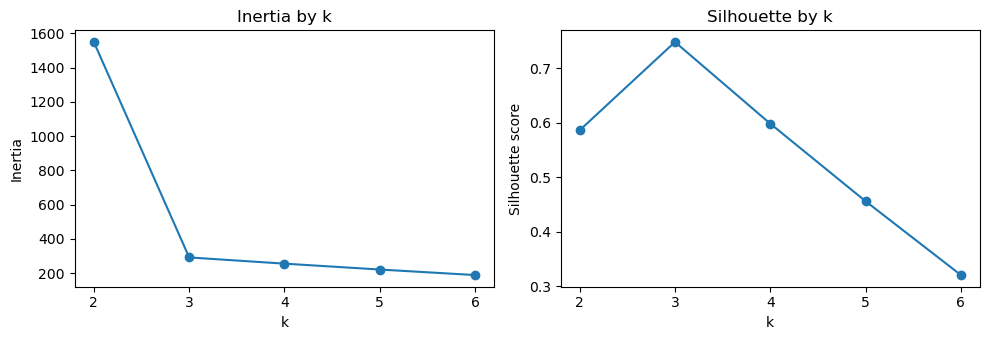

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(scores["k"], scores["inertia"], marker="o")
axes[0].set(xlabel="k", ylabel="Inertia", title="Inertia by k")
axes[1].plot(scores["k"], scores["silhouette"], marker="o")
axes[1].set(xlabel="k", ylabel="Silhouette score", title="Silhouette by k")
for ax in axes:
    ax.set_xticks(scores["k"])
plt.tight_layout()
plt.show()

### 최고 실루엣 점수의 `k`를 선택해 본다

`idxmax()`는 점수가 가장 높은 행을 찾는다. 군집을 학습한 뒤 **군집 크기와 중심의 해석 가능성**도 확인하라.

선택된 k: 3
군집 크기: {0: 80, 1: 80, 2: 80}


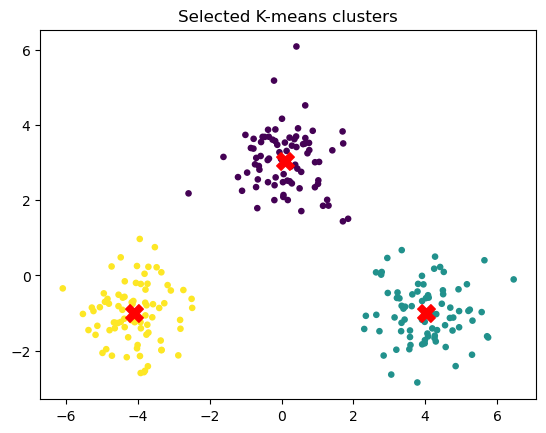

In [21]:
K = int(scores.loc[scores["silhouette"].idxmax(), "k"])
model = KMeans(n_clusters=K, n_init=10, random_state=42)
labels = model.fit_predict(X_blob)
print("선택된 k:", K)
print("군집 크기:", pd.Series(labels).value_counts().sort_index().to_dict())

plt.scatter(X_blob["x"], X_blob["y"], c=labels, s=14)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
            marker="X", s=160, c="red")
plt.title("Selected K-means clusters")
plt.show()

### 군집의 전형적인 점과 멀리 떨어진 점

`transform()`으로 모든 센트로이드까지의 거리를 구한 다음, 각 점의 **가장 가까운 센트로이드까지의 거리**를 확인할 수 있다. 이 값이 크다고 곧바로 오류라는 뜻은 아니다.

In [22]:
examples = X_blob.copy()
examples["cluster"] = labels
examples["center_distance"] = model.transform(X_blob).min(axis=1)

print("중심에 가까운 점")
print(examples.nsmallest(3, "center_distance").round(2))
print("중심에서 먼 점")
print(examples.nlargest(3, "center_distance").round(2))

중심에 가까운 점
        x     y  cluster  center_distance
228  4.00 -0.96        1             0.04
15  -0.02  3.09        0             0.13
194  4.18 -0.99        1             0.15
중심에서 먼 점
        x     y  cluster  center_distance
12   0.41  6.08        0             3.05
32  -2.59  2.18        0             2.83
167  6.46 -0.10        1             2.59


**확인 질문**

- `a=5`, `b=2`라면 실루엣 계수는 얼마인가? 음수 값은 무엇을 의미하는가?
- 관성이 가장 작은 `k`가 항상 가장 좋은 선택이 아닌 이유는 무엇인가?
- 최고 실루엣 점수의 `k`는 반드시 실제 군집 수일까?
- 중심에서 먼 점도 같은 군집에 남아 있을 수 있는가?

## 5단계: K-평균이 놓치는 군집 구조를 살펴본다

K-평균은 **센트로이드와의 거리**를 이용하므로 둥근 모양의 군집에 비교적 잘 맞는다. 굽은 모양이나 밀도가 크게 다른 군집에서는 결과가 기대와 다를 수 있다.

### K-평균 외의 방법도 비교한다

두 개의 초승달처럼 휘어진 모양의 데이터를 만들어 보자. **DBSCAN**은 밀집한 이웃 관계로 군집을 찾기 때문에 K-평균과 다른 결과를 낼 수 있다. **가우스 혼합 모델(GMM)**도 다른 군집화 방법 중 하나다. 여기서는 여러 모델이 존재한다는 사실만 확인한다.

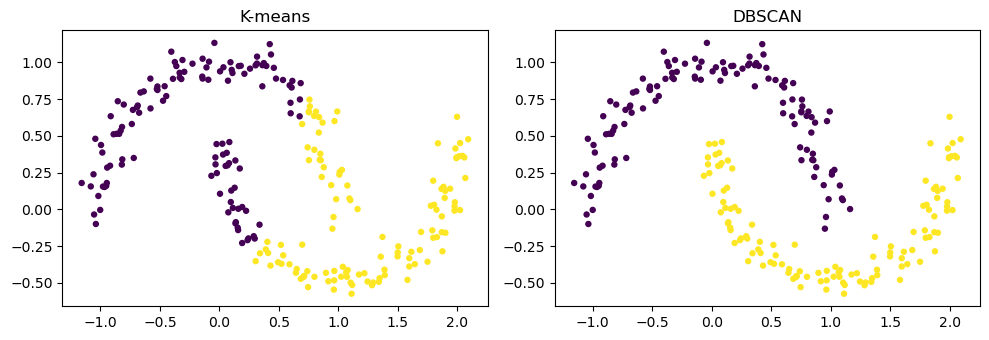

In [23]:
moons, _ = make_moons(n_samples=240, noise=0.07, random_state=42)
km_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(moons)
db_labels = DBSCAN(eps=0.22, min_samples=5).fit_predict(moons)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(moons[:, 0], moons[:, 1], c=km_labels, s=13)
axes[0].set_title("K-means")
axes[1].scatter(moons[:, 0], moons[:, 1], c=db_labels, s=13)
axes[1].set_title("DBSCAN")
plt.tight_layout()
plt.show()

**확인 질문**

- 두 그림에서 같은 데이터가 서로 다르게 묶이는 이유는 무엇인가?
- 이 데이터에서 K-평균의 한계를 어떻게 설명할 수 있는가?
- 군집의 모양이 다르면 다른 방법을 검토해야 하는 이유는 무엇인가?

## 실습 정리

| 수행한 작업 | 확인한 개념 |
|---|---|
| 붓꽃 자료를 레이블 없이 군집화 | 군집 번호는 정답 레이블이 아니다. |
| 할당 → 평균 갱신 → 재할당 계산 | K-평균은 중심과 배정을 반복해 갱신한다. |
| 방문객·만족도 표준화 전후의 거리 비교 | 특성별 단위와 크기가 거리 판단에 영향을 준다. |
| 판매건수와 행별 비중의 거리 비교 | 규모와 구성 비율은 서로 다른 유사성 기준이다. |
| 실루엣 계수 직접 계산, 관성·점수 비교 | 점수는 군집 수를 선택할 때 참고하는 지표다. |
| 중심에서 가까운 점과 먼 점 비교 | 같은 군집 안에도 차이가 남는다. |
| 초승달 데이터에 다른 방법 적용 | K-평균이 항상 적합한 것은 아니다. |

**최종 점검:** 코드의 출력과 그래프를 근거로, K-평균이 잘 작동하는 조건과 조심해야 할 조건을 각각 설명하라.